In [1]:
import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt

import tdgl
from tdgl.geometry import box

from shapely.geometry import Polygon as ShapelyPolygon
from shapely.ops import unary_union

#plot sizes
plt.rcParams["figure.figsize"] = (8, 10)
plt.rcParams["figure.dpi"] = 120

Probe points: [(0.0, 1.5), (0.0, -1.5)]


Constructing Voronoi polygons: 100%|██████████| 2570/2570 [00:00<00:00, 15238.47it/s]


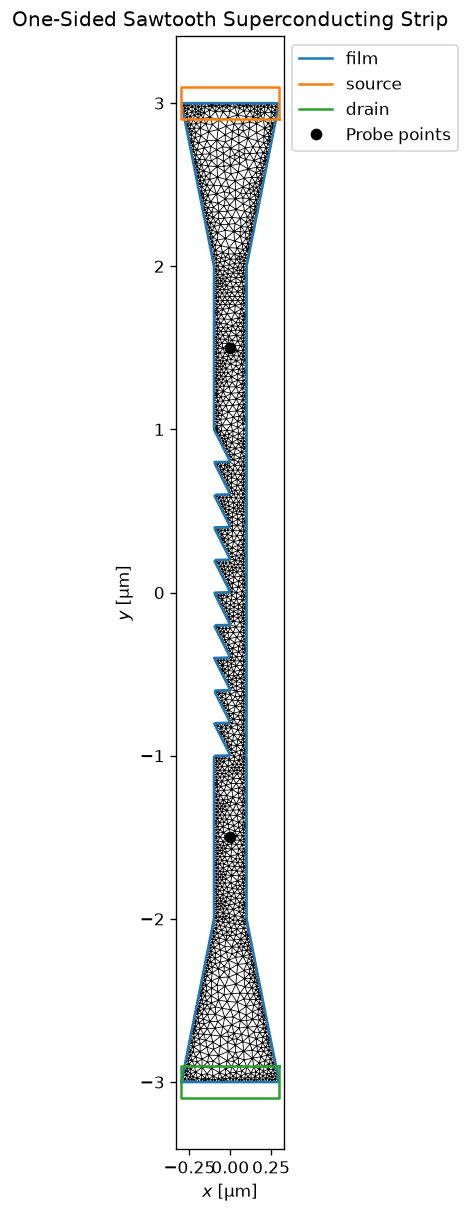

In [2]:
# =====================================================
# MATERIAL PARAMETERS
# =====================================================

layer = tdgl.Layer(
    coherence_length=0.011,
    london_lambda=0.125,
    thickness=0.030,
)

# =====================================================
# FILM DIMENSIONS
# =====================================================

W = 0.2
L = 2

# Sawtooth parameters
n_teeth = 10
tooth_depth = 0.1

lead_length = 1.0      # <-- change this to whatever you like
terminal_length = 0.2

# Funnel (trapezium) parameters
funnel_height = 1.0      # vertical height of each trapezium
terminal_width = 0.6     # width at the wide end

# =====================================================
# TRUE ALTERNATING SAWTOOTH EDGE: |/|/|/|/
# =====================================================

y_step = L / n_teeth

left_edge = [(-W/2, -L/2)]

for i in range(n_teeth):
    y0 = -L/2 + i * y_step
    y1 = -L/2 + (i + 1) * y_step

    # ramp down and back (safe geometry)
    left_edge.append((-W/2 + tooth_depth, y0 + 0.01 * y_step))
    left_edge.append((-W/2, y1))

right_edge = [(W/2, L/2), (W/2, -L/2)]

film_points = np.array(left_edge + right_edge)


# =====================================================
# RIGHT EDGE (flat)
# =====================================================
right_edge = [
    (W / 2, L / 2),
    (W / 2, -L / 2),
]


# =====================================================
# COMBINE FILM SHAPE
# =====================================================
film_points = np.array(
    left_edge +
    right_edge
)

film = (
    tdgl.Polygon(
        "film",
        points=film_points,
    )
    .resample(600)
)


# =====================================================
# LEADS (unchanged)
# =====================================================
bottom_lead = ShapelyPolygon([
    (-W/2, -L/2 - lead_length),
    ( W/2, -L/2 - lead_length),
    ( W/2, -L/2),
    (-W/2, -L/2),
])

bottom_funnel = ShapelyPolygon([
    (-W/2,             -L/2 - lead_length),
    ( W/2,             -L/2 - lead_length),
    ( terminal_width/2,-L/2 - lead_length - funnel_height),
    (-terminal_width/2,-L/2 - lead_length - funnel_height),
])

top_lead = ShapelyPolygon([
    (-W/2,  L/2),
    ( W/2,  L/2),
    ( W/2,  L/2 + lead_length),
    (-W/2,  L/2 + lead_length),
])

top_funnel = ShapelyPolygon([
    (-terminal_width/2, L/2 + lead_length + funnel_height),
    ( terminal_width/2, L/2 + lead_length + funnel_height),
    ( W/2,             L/2 + lead_length),
    (-W/2,             L/2 + lead_length),
])


# =====================================================
# MERGE SHAPES
# =====================================================
sawtooth = ShapelyPolygon(film.points)

combined = unary_union([
    sawtooth,
    bottom_lead,
    top_lead,
    bottom_funnel,
    top_funnel,
])

film = (
    tdgl.Polygon(
        "film",
        points=np.asarray(combined.exterior.coords)
    )
    .resample(800)
)

L_total = L + 2 * lead_length + 2 * funnel_height
# =====================================================
# TERMINALS
# =====================================================

source = (
    tdgl.Polygon(
        "source",
        points=box(terminal_width, terminal_length)
    )
    .translate(dy=L_total/2)
)

drain = (
    source
    .scale(yfact=-1)
    .set_name("drain")
)

# =====================================================
# MANUAL PROBE POINTS
# =====================================================

def get_manual_probe_points():
    # 👇 EDIT THESE DIRECTLY
    probe_points = [
        (0.0, 1.5), 
        (0.00, -1.5)
    ]
    return probe_points


probe_points = get_manual_probe_points()

print("Probe points:", probe_points)

# =====================================================
# DEVICE
# =====================================================

device = tdgl.Device(
    "one_sided_sawtooth",
    layer=layer,
    film=film,
    holes=[],
    terminals=[source, drain],
    probe_points=probe_points,
)

# =====================================================
# MESH
# =====================================================

device.make_mesh(
    max_edge_length=0.075, #normal 0.25
    smooth=50,            #normal 50
)

fig, ax = device.plot(mesh=True)

ax.set_aspect("equal")
ax.set_title("One-Sided Sawtooth Superconducting Strip")

plt.show()

# =====================================================
# 8. OUTPUT FILE (🔴 FIX FOR YOUR ERROR)
# =====================================================

tempdir = tempfile.TemporaryDirectory()
output_path = os.path.join(tempdir.name, "tdgl_run.h5")

# =====================================================
# 9. SOLVER OPTIONS
# =====================================================

options = tdgl.SolverOptions(
    solve_time=1000,
    dt_init=0.05,
    save_every=100,
    output_file=output_path,   # 🔴 REQUIRED FOR ANIMATION
)


Simulating: 100%|█████████▉| 1000/1000 [00:04<00:00, 241.39tau/s ]


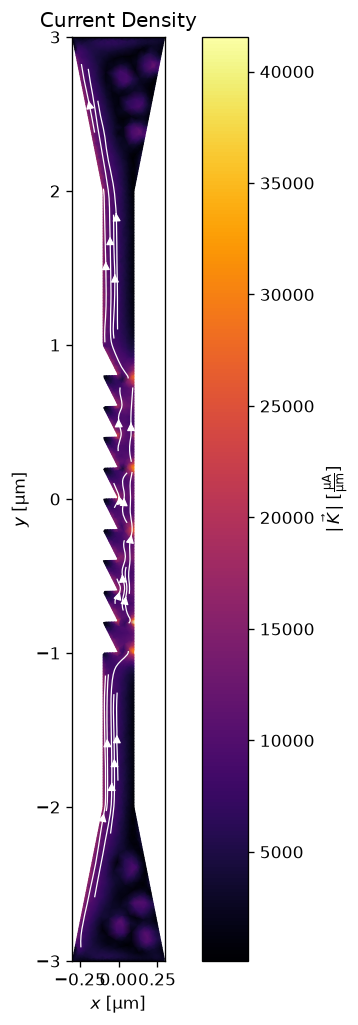

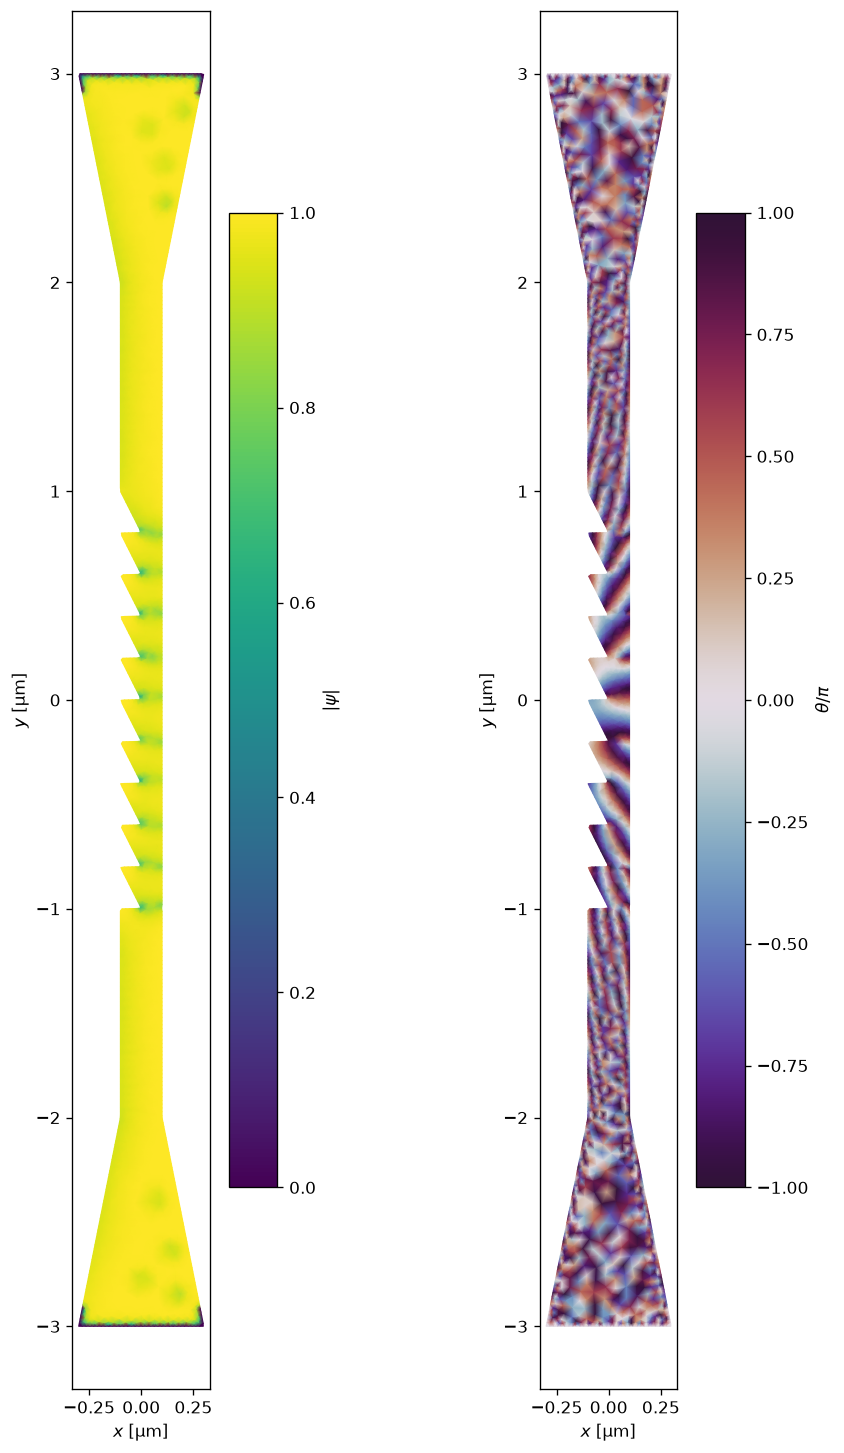

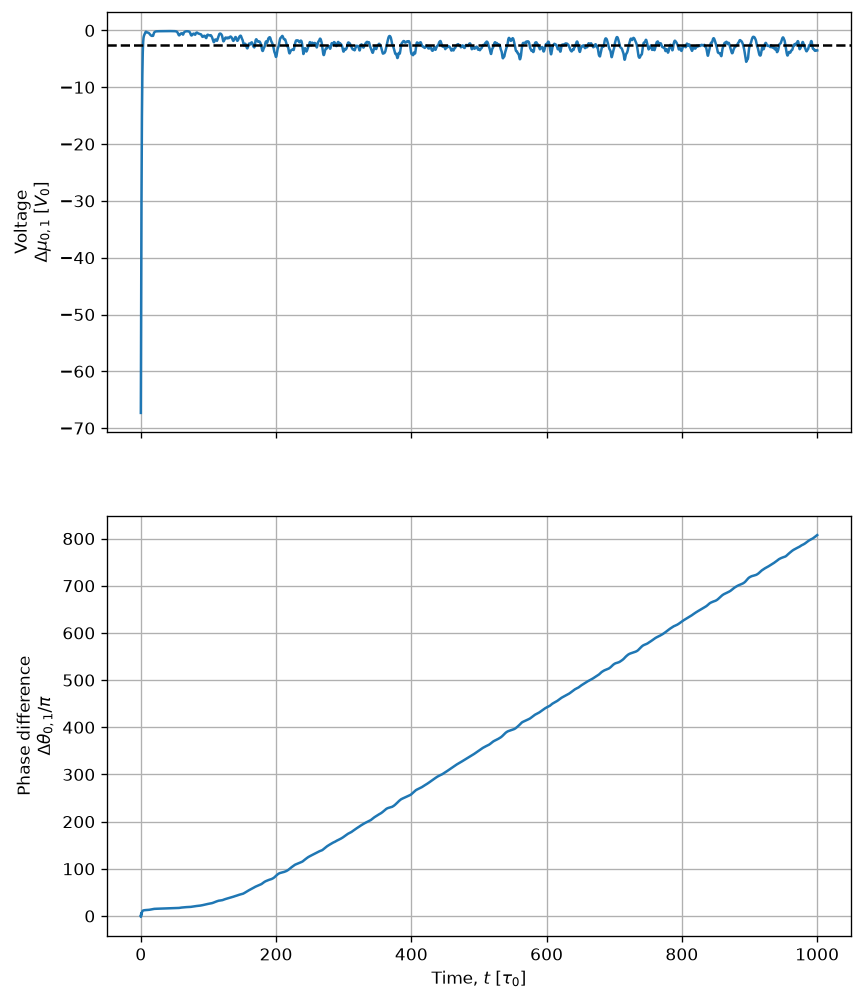

TypeError: an integer is required

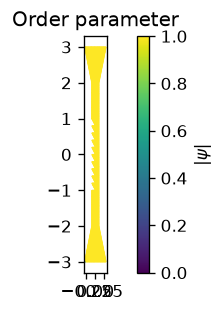

In [3]:


# =====================================================
# TDGL SOLVE
# =====================================================

solution = tdgl.solve(
    device,
    options,
    applied_vector_potential=50,
    terminal_currents={
        "source":-1500,
        "drain": 1500,
    },
)

# =====================================================
# CURRENT DENSITY
# =====================================================

fig, ax = solution.plot_currents()

try:
    ax.set_title("Current Density")
except Exception:
    pass

plt.show()

# =====================================================
# ORDER PARAMETER
# =====================================================

result = solution.plot_order_parameter()

if isinstance(result, tuple):
    fig, axes = result
else:
    fig, axes = plt.gcf(), result

# FORCE FIGURE SIZE AFTER CREATION (this is the key)
fig.set_size_inches(8, 12)   # <-- increase height for vertical space
fig.set_dpi(120)

plt.show()

# =====================================================
# DYNAMICS (IF AVAILABLE)
# =====================================================

if hasattr(solution, "dynamics"):

    try:
        fig, axes = solution.dynamics.plot()
        plt.show()
    except Exception as e:
        print("Dynamics plot unavailable:", e)
        
# =====================================================
# 12. ANIMATION (FIXED VERSION)
# =====================================================

import h5py
import os
from tdgl.visualization.animate import create_animation
from IPython.display import Image, display

with tdgl.non_gui_backend():
    with h5py.File(output_path, "r") as h5file:

        anim = create_animation(
            h5file,
            quantities=["order_parameter"],
            fps=20,
        )

        # Save GIF to the notebook's current folder
        gif_path = os.path.abspath("movement.gif")

        anim.save(
            gif_path,
            writer="pillow",
            fps=20,
            dpi=200   #  res
        )

        print(f"GIF saved to:\n{gif_path}")

        display(Image(filename=gif_path))
# =====================================================
# CLEANUP
# =====================================================

tempdir.cleanup()

print("Simulation complete.")

Probe points: [(0.0, 1.5), (0.0, -1.5)]


Constructing Voronoi polygons: 100%|██████████| 2489/2489 [00:00<00:00, 8865.03it/s]


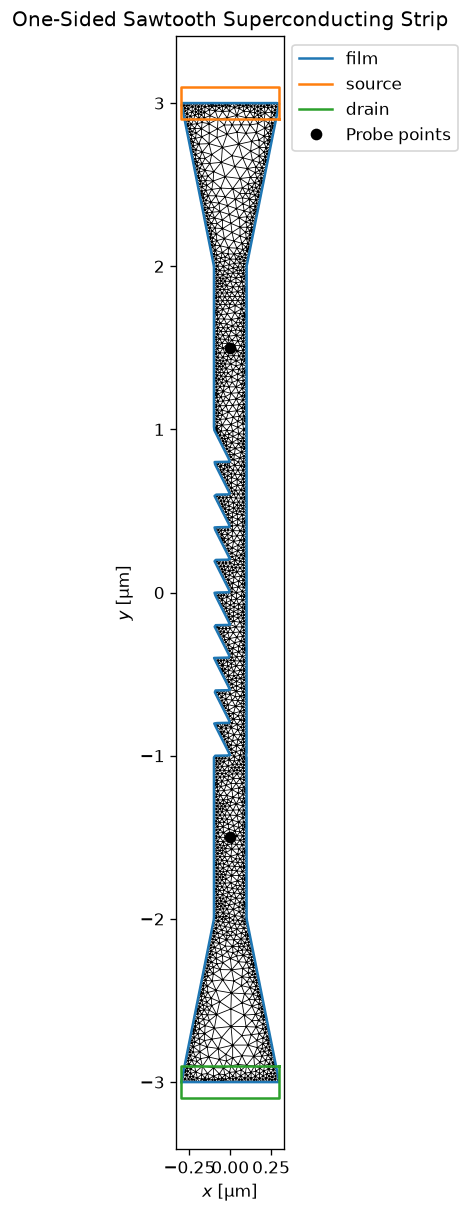

Simulating: 100%|█████████▉| 150/150 [1:39:24<00:00, 39.76s/tau ]         


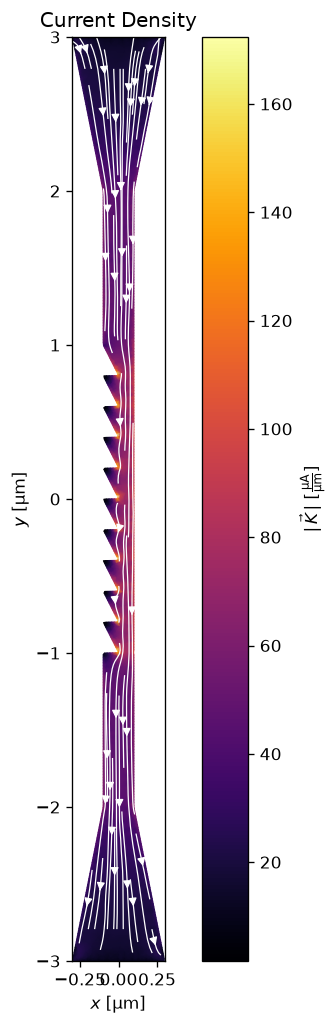

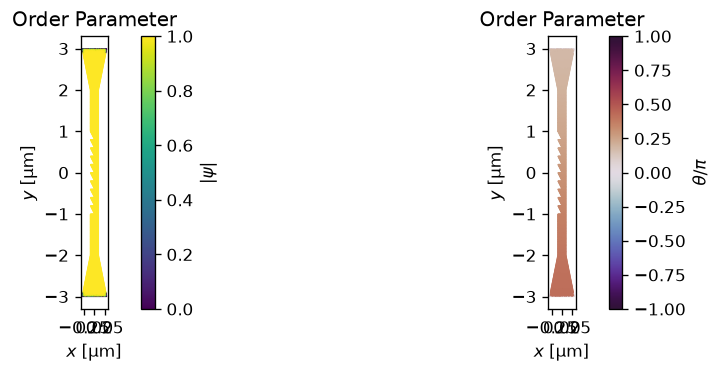

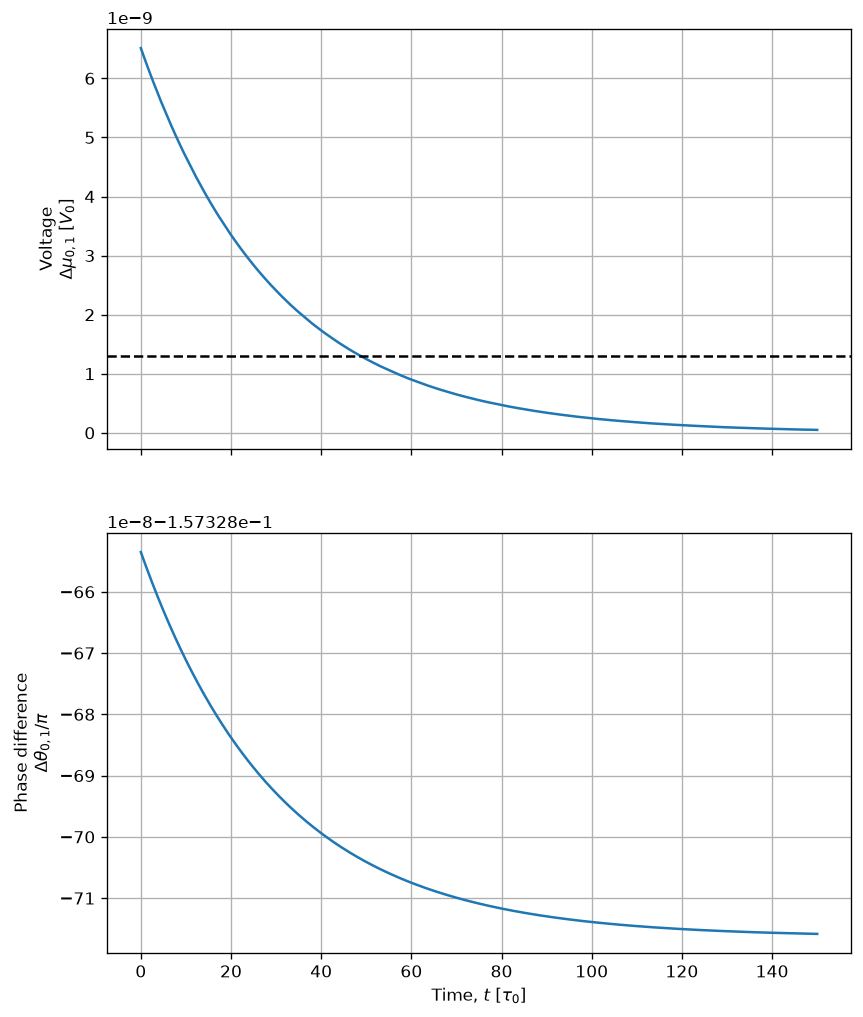

✔ Complex TDGL simulation completed successfully


In [ ]:
# screening script

import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt

import tdgl
from tdgl.geometry import box, circle

# =====================================================
# MATERIAL PARAMETERS
# =====================================================

layer = tdgl.Layer(
    coherence_length=0.011,
    london_lambda=0.125,
    thickness=0.030,
)

# =====================================================
# VECTOR OUTPUT SETTINGS (for saving the files)
# =====================================================

plt.rcParams["pdf.fonttype"] = 42   # embed fonts as text, not outlines/curves
plt.rcParams["ps.fonttype"] = 42    # (so text stays editable in Illustrator/Inkscape)
plt.rcParams["svg.fonttype"] = "none"

# =====================================================
# FILM DIMENSIONS
# =====================================================

W = 0.2
L = 2

# Sawtooth parameters
n_teeth = 10
tooth_depth = 0.1

lead_length = 1.0      # <-- change this to whatever you like
terminal_length = 0.2

# Funnel (trapezium) parameters
funnel_height = 1.0      # vertical height of each trapezium
terminal_width = 0.6     # width at the wide end

# =====================================================
# TRUE ALTERNATING SAWTOOTH EDGE: |/|/|/|/
# =====================================================

y_step = L / n_teeth

left_edge = [(-W/2, -L/2)]

for i in range(n_teeth):
    y0 = -L/2 + i * y_step
    y1 = -L/2 + (i + 1) * y_step

    # ramp down and back (safe geometry)
    left_edge.append((-W/2 + tooth_depth, y0 + 0.01 * y_step))
    left_edge.append((-W/2, y1))

right_edge = [(W/2, L/2), (W/2, -L/2)]

film_points = np.array(left_edge + right_edge)


# =====================================================
# RIGHT EDGE (flat)
# =====================================================
right_edge = [
    (W / 2, L / 2),
    (W / 2, -L / 2),
]


# =====================================================
# COMBINE FILM SHAPE
# =====================================================
film_points = np.array(
    left_edge +
    right_edge
)

film = (
    tdgl.Polygon(
        "film",
        points=film_points,
    )
    .resample(600)
)


# =====================================================
# LEADS (unchanged)
# =====================================================
bottom_lead = ShapelyPolygon([
    (-W/2, -L/2 - lead_length),
    ( W/2, -L/2 - lead_length),
    ( W/2, -L/2),
    (-W/2, -L/2),
])

bottom_funnel = ShapelyPolygon([
    (-W/2,             -L/2 - lead_length),
    ( W/2,             -L/2 - lead_length),
    ( terminal_width/2,-L/2 - lead_length - funnel_height),
    (-terminal_width/2,-L/2 - lead_length - funnel_height),
])

top_lead = ShapelyPolygon([
    (-W/2,  L/2),
    ( W/2,  L/2),
    ( W/2,  L/2 + lead_length),
    (-W/2,  L/2 + lead_length),
])

top_funnel = ShapelyPolygon([
    (-terminal_width/2, L/2 + lead_length + funnel_height),
    ( terminal_width/2, L/2 + lead_length + funnel_height),
    ( W/2,             L/2 + lead_length),
    (-W/2,             L/2 + lead_length),
])


# =====================================================
# MERGE SHAPES
# =====================================================
sawtooth = ShapelyPolygon(film.points)

combined = unary_union([
    sawtooth,
    bottom_lead,
    top_lead,
    bottom_funnel,
    top_funnel,
])

film = (
    tdgl.Polygon(
        "film",
        points=np.asarray(combined.exterior.coords)
    )
    .resample(800)
)

L_total = L + 2 * lead_length + 2 * funnel_height
# =====================================================
# TERMINALS
# =====================================================

source = (
    tdgl.Polygon(
        "source",
        points=box(terminal_width, terminal_length)
    )
    .translate(dy=L_total/2)
)

drain = (
    source
    .scale(yfact=-1)
    .set_name("drain")
)

# =====================================================
# MANUAL PROBE POINTS
# =====================================================

def get_manual_probe_points():
                                            #You can EDIT THESE DIRECTLY
    probe_points = [
        (0.0, 1.5), 
        (0.00, -1.5)
    ]
    return probe_points


probe_points = get_manual_probe_points()

print("Probe points:", probe_points)

# =====================================================
# DEVICE
# =====================================================

device = tdgl.Device(
    "one_sided_sawtooth",
    layer=layer,
    film=film,
    holes=[],
    terminals=[source, drain],
    probe_points=probe_points,
)

# =====================================================
# MESH
# =====================================================

device.make_mesh(
    max_edge_length=0.25,
    smooth=50,
)

fig, ax = device.plot(mesh=True)

ax.set_aspect("equal")
ax.set_title("One-Sided Sawtooth Superconducting Strip")

plt.show()
# =====================================================
# 8. SOLVER SETUP
# =====================================================
tempdir = tempfile.TemporaryDirectory()

options = tdgl.SolverOptions(
    skip_time=50,
    solve_time=150,
    output_file=os.path.join(tempdir.name, "complex_device.h5"),
    include_screening=True,
    screening_tolerance=1e-4,
    dt_max=1e-3,
)

# =====================================================
# 9. RUN SIMULATION
# =====================================================
solution = tdgl.solve(
    device,
    options,
    applied_vector_potential=0.00,  # mT?
    terminal_currents={
        "source": 10.0,  #150 at 0.05 ~Ic
        "drain": -10.0,
    },
)

# =====================================================
# 10. CURRENT DENSITY
# =====================================================
fig, ax = solution.plot_currents()
ax.set_title("Current Density")
plt.show()

# =====================================================
# 11. ORDER PARAMETER (ROBUST AXIS HANDLING)
# =====================================================
result = solution.plot_order_parameter()

if isinstance(result, tuple):
    fig, axes = result
else:
    fig, axes = plt.gcf(), result

try:
    axes_list = axes.flat
except AttributeError:
    axes_list = [axes]

for a in axes_list:
    a.set_title("Order Parameter")

plt.show()

# =====================================================
# 12. DYNAMICS (if available)
# =====================================================
if hasattr(solution, "dynamics"):
    fig, axes = solution.dynamics.plot()
    plt.show()

# =====================================================
# 13. CLEANUP
# =====================================================
tempdir.cleanup()

print("✔ Complex TDGL simulation completed successfully")